In [2]:
from google.colab import files

uploaded = files.upload()

Saving Consolidado_ambiental_nodos_Comuna_22_AD.xlsx to Consolidado_ambiental_nodos_Comuna_22_AD (1).xlsx


In [3]:
import pandas as pd

ruta_archivo = '/content/Consolidado_ambiental_nodos_Comuna_22_AD.xlsx'

df = pd.read_excel(ruta_archivo, sheet_name="Datos semanales")
dic = pd.read_excel(ruta_archivo, sheet_name="Diccionario")

In [4]:
import numpy as np


In [5]:
print(df.shape) # fase de conocimiento de los datos
print(df.dtypes.value_counts()) # cuantos tipos de variables hay y cuantos hay de cada una
print(df.groupby("nodo").size())# agrupar los datos por nodo para su mejor procesamiento
print(sorted(set(range(1, 19)) - set(df["nodo"])))# cuales nodos faltan
print(df["inicio_semana"].min(), df["inicio_semana"].max())# que periodo cubre el estudio cual es el rango

(2873, 49)
float64           38
int64              9
datetime64[ns]     2
Name: count, dtype: int64
nodo
1     169
2     169
3     169
4     169
5     169
6     169
7     169
8     169
10    169
11    169
12    169
13    169
14    169
15    169
16    169
17    169
18    169
dtype: int64
[9]
2023-06-26 00:00:00 2026-09-14 00:00:00


In [6]:
print("Filas duplicadas:", df.duplicated().sum())# cuantos datos duplicados hay
print("Duplicados nodo+semana:", df.duplicated(["nodo", "inicio_semana"]).sum()) #cuenta repeticiones del mismo nodo en la misma semana; cada combinación debe ser única

iso = df["inicio_semana"].dt.isocalendar() # calcula año y semana ISO a partir de la fecha; sirve para verificar las columnas año y semana
print("No lunes:", (df["inicio_semana"].dt.dayofweek != 0).sum()) # cuenta fechas de inicio que no son lunes (lunes = 0); deben ser 0 según el diccionario
print("fin != inicio+6:", ((df["fin_semana"] - df["inicio_semana"]).dt.days != 6).sum()) # cuenta semanas que no duran 7 días (inicio + 6 = fin); deben ser 0
print("Año/semana ISO inconsistentes:", # cuenta filas donde año o semana no coinciden con la fecha; deben ser 0
      ((iso.year != df["año"]) | (iso.week != df["semana"])).sum())

Filas duplicadas: 0
Duplicados nodo+semana: 0
No lunes: 0
fin != inicio+6: 0
Año/semana ISO inconsistentes: 0


In [ ]:
falt = df.isna().sum().to_frame("n_NA")  # cuenta los vacíos (NA) de cada columna y los pone en una tabla
falt["pct"] = (falt["n_NA"] / len(df) * 100).round(2)  # convierte ese conteo en porcentaje del total de filas; permite comparar columnas
print(falt[falt["n_NA"] > 0])  # muestra solo las columnas que sí tienen faltantes; evita imprimir 49 líneas
print("Filas con algún NA:", df.isna().any(axis=1).sum())  # cuenta filas con al menos un vacío; dice cuántas observaciones están incompletas
print(df.isna().sum(axis=1).groupby(df["nodo"]).sum())  # suma los vacíos por nodo; revela si el problema se concentra en pocos sensores (15 y 16)

In [ ]:
grupos = {  # diccionario con los tres valores de cada variable (mínimo, media, máximo)
    "temperatura": ("temperatura_min_c", "temperatura_media_c", "temperatura_max_c"),  # temperatura
    "humedad": ("humedad_min_pct", "humedad_media_pct", "humedad_max_pct"),  # humedad relativa
    "viento": ("viento_min", "viento_medio", "viento_max"),  # velocidad del viento
    "ruido": ("ruido_min_db", "ruido_medio_db", "ruido_max_db"),  # ruido en decibelios
    "pm25": ("pm25_min", "pm25_media", "pm25_max"),  # material particulado fino
    "pm10": ("pm10_min", "pm10_media", "pm10_max"),  # material particulado grueso
}  # cierra el diccionario
for nombre, (mn, md, mx) in grupos.items():  # recorre cada variable con su mínimo, media y máximo
    mal = (df[mn] > df[md]) | (df[md] > df[mx])  # marca las filas donde el mínimo supera a la media o la media supera al máximo (imposible)
    print(nombre, int(mal.sum()))  # imprime cuántas filas incoherentes tiene cada variable
print("PM2.5 media > PM10 media:", (df["pm25_media"] > df["pm10_media"]).sum())  # PM2.5 está contenido en PM10, así que su media no puede ser mayor

In [ ]:
import matplotlib.pyplot as plt  # librería para hacer gráficos

print(df[["temperatura_media_c", "humedad_media_pct", "radiacion_media", "pm25_media", "ruido_medio_db", "huevos_aedes"]].describe().round(2))  # resumen (promedio, mínimo, máximo) de las variables clave; los máximos absurdos se ven aquí
print("Temperatura > 50:", (df["temperatura_max_c"] > 50).sum())  # cuenta temperaturas imposibles (6)
print("Humedad media = 0:", (df["humedad_media_pct"] == 0).sum())  # cuenta humedades medias de 0 % (5)
print("Radiación media = 0:", (df["radiacion_media"] == 0).sum())  # cuenta radiaciones medias de 0 (2)
print("PM2.5 máximo = 1000:", (df["pm25_max"] == 1000).sum())  # cuenta semanas donde PM2.5 llegó al tope del sensor (114)
df.boxplot(column="pm25_media")  # dibuja un boxplot de PM2.5; los puntos aislados arriba son valores atípicos
plt.show()  # muestra el gráfico en pantalla

In [ ]:
print("Lecturas > 672:", (df["lecturas_surth"] > 672).sum())  # cuenta semanas con más lecturas de las posibles en 7 días (288)
print("Cobertura < 50 %:", (df["cobertura_min_pct"] < 50).sum())  # cuenta semanas con menos de la mitad de las lecturas (131)
print("Cobertura = 0 %:", (df["cobertura_min_pct"] == 0).sum())  # cuenta semanas sin ninguna lectura (3)

In [ ]:
# 1) Temperatura imposible
fila_mala = df["temperatura_max_c"] > 50  # busca las filas donde la temperatura máxima pasa de 50 °C; en Cali eso es imposible, es error del sensor
df.loc[fila_mala, ["temperatura_media_c", "temperatura_min_c", "temperatura_max_c", "amplitud_termica_c"]] = np.nan  # en esas filas deja vacías las 4 columnas de temperatura; la amplitud también, porque se calcula con la temperatura dañada
df.loc[df["temperatura_2sem_previas_c"] > 50, "temperatura_2sem_previas_c"] = np.nan  # el error también se coló en el promedio de las 2 semanas previas; se borra para que no se propague

# 2) Humedad imposible
df.loc[df["humedad_media_pct"] == 0, "humedad_media_pct"] = np.nan  # una semana no puede tener humedad promedio de 0 %, así que se deja vacía

# 3) Radiación imposible
df.loc[df["radiacion_media"] == 0, "radiacion_media"] = np.nan  # una semana no puede tener radiación promedio de 0, así que se deja vacía

# Guardar
df.to_excel("base_limpia.xlsx", index=False)  # guarda la base limpia en un Excel nuevo; el archivo original no se modifica

In [8]:
import pandas as pd  # librería para manejar tablas de datos
import numpy as np  # librería para cálculos numéricos
import matplotlib.pyplot as plt  # librería para hacer gráficos
from scipy import stats  # librería de estadística; trae Shapiro-Wilk y los Q-Q plots
import os  # para crear la carpeta donde se guardan los gráficos

ruta_archivo = "base_limpia.xlsx"  # cambiamos a la ruta local donde se guardó en el paso anterior

# Si ya está df en memoria, lo usamos; de lo contrario, lo leemos del archivo excel
try:
    if 'df' in globals() and df.shape == (2873, 49):
        print("Usando el DataFrame 'df' ya cargado en memoria.")
    else:
        df = pd.read_excel(ruta_archivo)
except FileNotFoundError:
    # En caso de que no se haya ejecutado la celda anterior en esta sesión, la volvemos a guardar
    df.to_excel(ruta_archivo, index=False)
    df = pd.read_excel(ruta_archivo)

print(df.shape)  # confirma que quedaron las 2873 filas y 49 columnas

Usando el DataFrame 'df' ya cargado en memoria.
(2873, 49)


In [9]:
ids = ["nodo", "año", "semana", "inicio_semana", "fin_semana"]  # columnas que identifican la observación; no son variables para describir
num = [c for c in df.select_dtypes("number").columns if c not in ids]  # todas las variables numéricas que no son identificadores; conserva el orden de la base
print(len(num), "variables numéricas para el análisis univariado")  # cuántas variables se van a analizar
print(num)  # lista de variables; sirve para revisar que no quedó ninguna de más o de menos

44 variables numéricas para el análisis univariado
['latitud', 'longitud', 'temperatura_media_c', 'humedad_media_pct', 'radiacion_media', 'uv_media', 'viento_medio', 'ruido_medio_db', 'pm25_media', 'pm10_media', 'temperatura_min_c', 'humedad_min_pct', 'viento_min', 'ruido_min_db', 'pm25_min', 'pm10_min', 'temperatura_max_c', 'humedad_max_pct', 'radiacion_max', 'uv_max', 'viento_max', 'ruido_max_db', 'pm25_max', 'pm10_max', 'amplitud_termica_c', 'precipitacion_semanal', 'dias_con_lluvia', 'intervalos_lluvia', 'lecturas_surth', 'cobertura_surth_pct', 'lecturas_wind', 'cobertura_wind_pct', 'lecturas_noise', 'cobertura_noise_pct', 'lecturas_mass', 'cobertura_mass_pct', 'cobertura_min_pct', 'precipitacion_semana_previa', 'precipitacion_2sem_previas', 'precipitacion_4sem_previas', 'temperatura_2sem_previas_c', 'humedad_2sem_previas_pct', 'pm25_2sem_previas', 'huevos_aedes']


In [10]:
desc = pd.DataFrame(index=num)  # tabla vacía con una fila por variable
desc["n"] = df[num].count()  # datos válidos (sin contar vacíos)
desc["n_NA"] = df[num].isna().sum()  # cuenta los vacíos de cada variable
desc["pct_NA"] = (desc["n_NA"] / len(df) * 100)  # porcentaje de vacíos sobre el total de filas
desc["media"] = df[num].mean()  # promedio
desc["mediana"] = df[num].median()  # valor central; si se aleja de la media hay asimetría o valores extremos
desc["desv"] = df[num].std()  # desviación estándar muestral
desc["CV_pct"] = (desc["desv"] / desc["media"].abs() * 100).replace([np.inf, -np.inf], np.nan)  # coeficiente de variación; compara la dispersión entre variables con distintas unidades (si la media es 0 queda vacío)
desc["min"] = df[num].min()  # valor mínimo
desc["Q1"] = df[num].quantile(0.25)  # primer cuartil (25 % de los datos por debajo)
desc["Q3"] = df[num].quantile(0.75)  # tercer cuartil (75 % de los datos por debajo)
desc["max"] = df[num].max()  # valor máximo
desc["rango"] = desc["max"] - desc["min"]  # rango = máximo - mínimo
desc["IQR"] = desc["Q3"] - desc["Q1"]  # rango intercuartílico; es lo que usa el boxplot para marcar atípicos
desc["n_atipicos"] = ((df[num] < desc["Q1"] - 1.5 * desc["IQR"]) | (df[num] > desc["Q3"] + 1.5 * desc["IQR"])).sum()  # cuenta los puntos fuera de los bigotes del boxplot (regla 1.5 x IQR)
desc["pct_ceros"] = (df[num] == 0).sum() / desc["n"] * 100  # porcentaje de ceros; importante en lluvia y huevos de Aedes
desc["asimetria"] = df[num].skew()  # asimetría (skewness); 0 = simétrica, > 0 cola a la derecha, < 0 cola a la izquierda
desc["curtosis"] = df[num].kurt()  # curtosis en exceso (kurtosis); 0 = como la normal, > 0 colas pesadas, < 0 colas livianas

pd.set_option("display.width", 250)  # ancho de la consola para que la tabla no se parta
pd.set_option("display.max_columns", None)  # muestra todas las columnas
pd.set_option("display.max_rows", None)  # muestra todas las filas (una por variable)
print(desc[["n", "n_NA", "pct_NA", "media", "mediana", "desv", "CV_pct"]].round(2))  # primer bloque: centro y dispersión
print(desc[["min", "Q1", "Q3", "max", "rango", "IQR", "n_atipicos", "pct_ceros"]].round(2))  # segundo bloque: posición, rango y atípicos

                                n  n_NA  pct_NA    media  mediana    desv   CV_pct
latitud                      2873     0    0.00     3.35     3.35    0.02     0.56
longitud                     2873     0    0.00   -76.54   -76.54    0.01     0.01
temperatura_media_c          2864     9    0.31    25.72    24.63   24.73    96.15
humedad_media_pct            2864     9    0.31    74.85    75.43    7.01     9.36
radiacion_media              2864     9    0.31   173.19   170.78   68.49    39.54
uv_media                     2864     9    0.31     1.79     1.76    0.81    45.28
viento_medio                 2869     4    0.14     2.39     2.31    1.19    49.93
ruido_medio_db               2868     5    0.17    51.27    49.01    7.91    15.44
pm25_media                   2868     5    0.17    11.94    10.17   22.93   192.05
pm10_media                   2868     5    0.17    11.95    10.22   22.56   188.84
temperatura_min_c            2864     9    0.31    20.47    19.40   24.90   121.65
hume

In [11]:
sw_W, sw_p = {}, {}  # diccionarios donde se guarda el estadístico W y el valor p de cada variable
for v in num:  # recorre cada variable numérica
    x = df[v].dropna()  # quita los vacíos; Shapiro-Wilk no los acepta
    if x.nunique() > 1:  # solo se puede probar si la variable no es constante
        sw_W[v], sw_p[v] = stats.shapiro(x)  # prueba de Shapiro-Wilk; H0: los datos vienen de una normal
    else:  # si es constante no hay nada que probar
        sw_W[v], sw_p[v] = np.nan, np.nan  # se deja vacío
desc["W_shapiro"] = pd.Series(sw_W)  # estadístico W; entre más cerca de 1, más parecida a una normal
desc["p_shapiro"] = pd.Series(sw_p)  # valor p; si es < 0.05 se rechaza la normalidad
desc["normal"] = np.where(desc["p_shapiro"] > 0.05, "Sí", "No")  # conclusión de la prueba con alfa = 0.05

desc["forma_asimetria"] = pd.cut(desc["asimetria"], [-np.inf, -1, -0.5, 0.5, 1, np.inf], labels=["fuerte izq.", "moderada izq.", "simétrica", "moderada der.", "fuerte der."]).astype(str)  # clasifica la asimetría con los cortes de 0.5 y 1
desc["forma_curtosis"] = pd.cut(desc["curtosis"], [-np.inf, -0.5, 0.5, np.inf], labels=["platicúrtica", "mesocúrtica", "leptocúrtica"]).astype(str)  # clasifica la curtosis: colas livianas, normal o colas pesadas

forma = desc[["asimetria", "forma_asimetria", "curtosis", "forma_curtosis", "W_shapiro", "p_shapiro", "normal"]].copy()  # copia de las columnas de forma y normalidad para imprimirlas
forma["p_shapiro"] = forma["p_shapiro"].map("{:.2e}".format)  # valor p en notación científica; con n grande casi todos son ~0 y round() los mostraría como 0.0
print(forma.round(4))  # tabla de forma y normalidad
print("Variables normales (p > 0.05):", list(desc.index[desc["normal"] == "Sí"]))  # cuáles pasan la prueba
print("Variables con asimetría fuerte (|a| > 1):", (desc["asimetria"].abs() > 1).sum(), "de", len(desc))  # cuántas tienen una cola muy marcada
print(desc["asimetria"].abs().sort_values(ascending=False).head(5).round(2))  # las 5 más asimétricas; suelen ser PM2.5, PM10, lluvia y huevos

                             asimetria forma_asimetria   curtosis forma_curtosis  W_shapiro p_shapiro normal
latitud                         0.7734   moderada der.     0.2014    mesocúrtica     0.9167  3.68e-37     No
longitud                       -0.1671       simétrica    -1.1481   platicúrtica     0.9349  1.03e-33     No
temperatura_media_c            23.6955     fuerte der.   562.6001   leptocúrtica     0.0351  1.16e-80     No
humedad_media_pct              -2.1982     fuerte izq.    21.2847   leptocúrtica     0.8879  1.82e-41     No
radiacion_media                 4.1686     fuerte der.    25.4940   leptocúrtica     0.6216  5.50e-62     No
uv_media                        4.8147     fuerte der.    34.2674   leptocúrtica     0.5748  3.58e-64     No
viento_medio                    0.2187       simétrica    -0.7606   platicúrtica     0.9802  1.44e-19     No
ruido_medio_db                  0.2335       simétrica    -1.1591   platicúrtica     0.9354  1.35e-33     No
pm25_media         

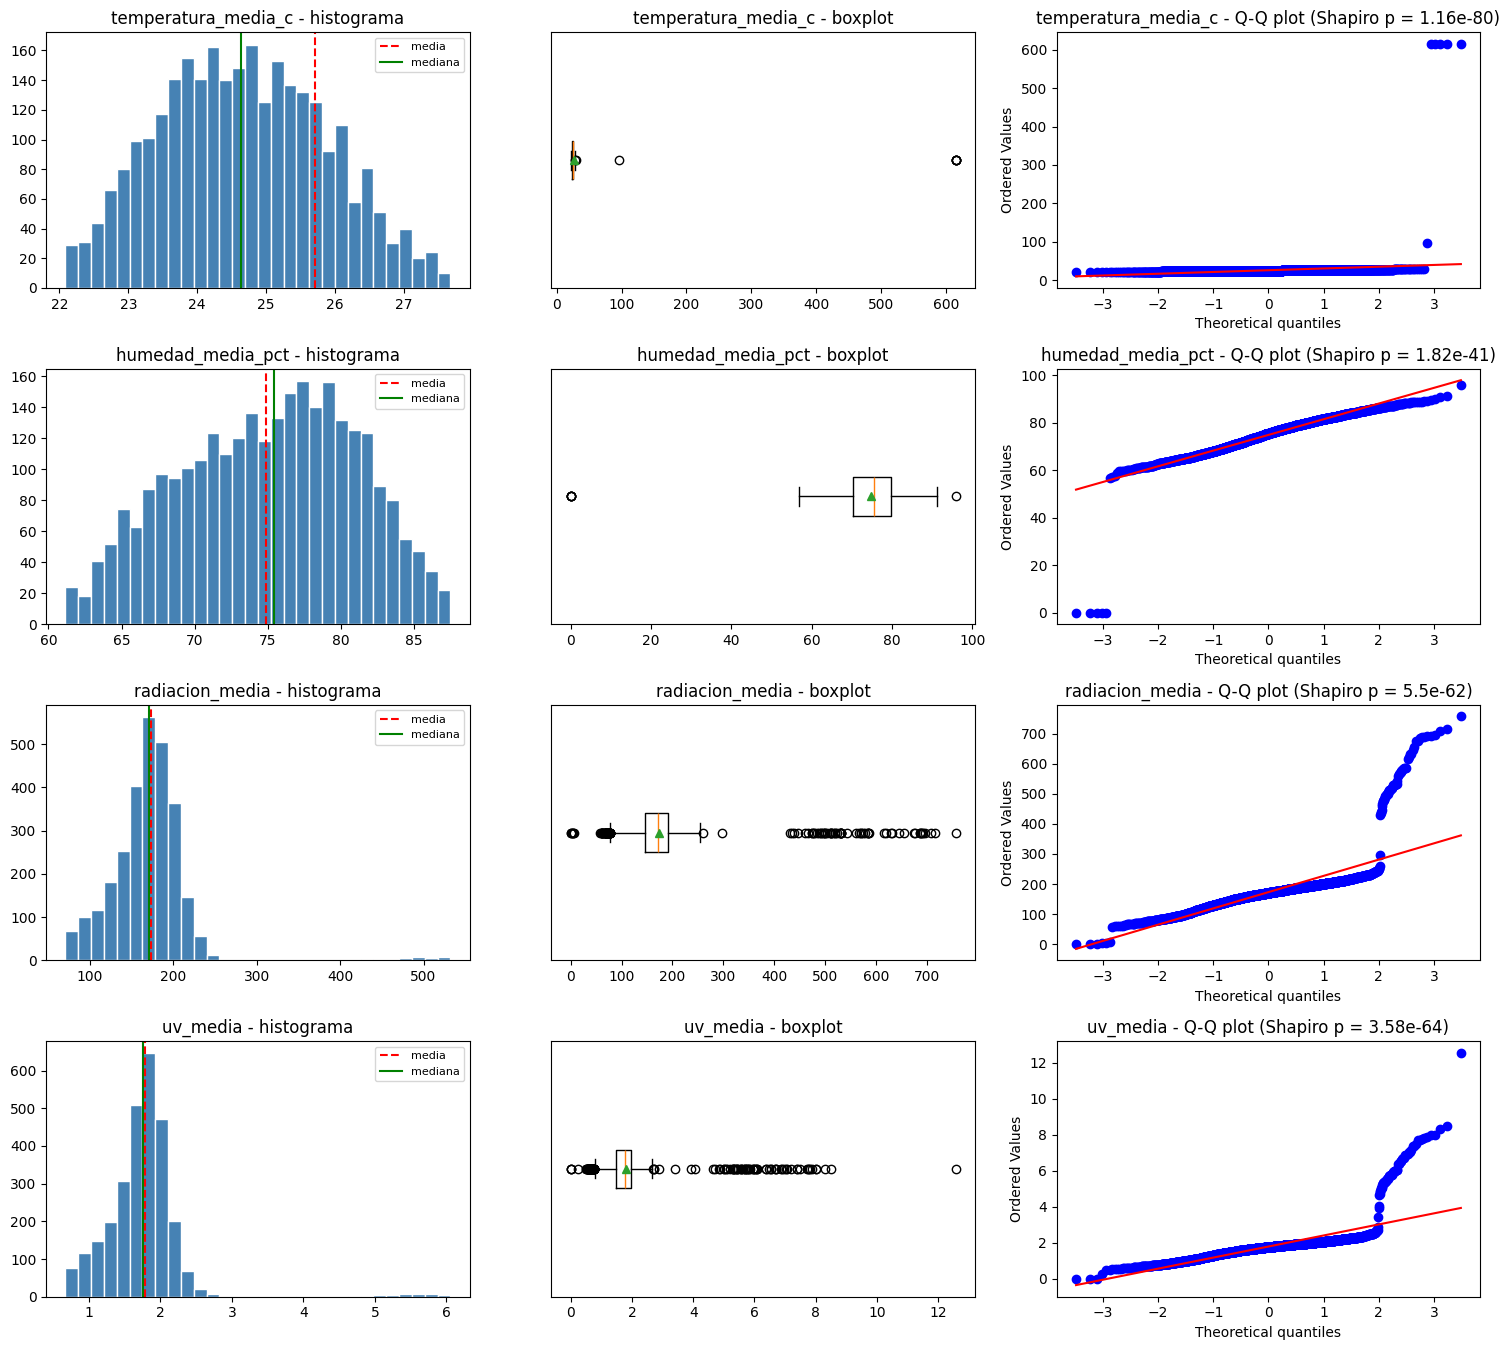

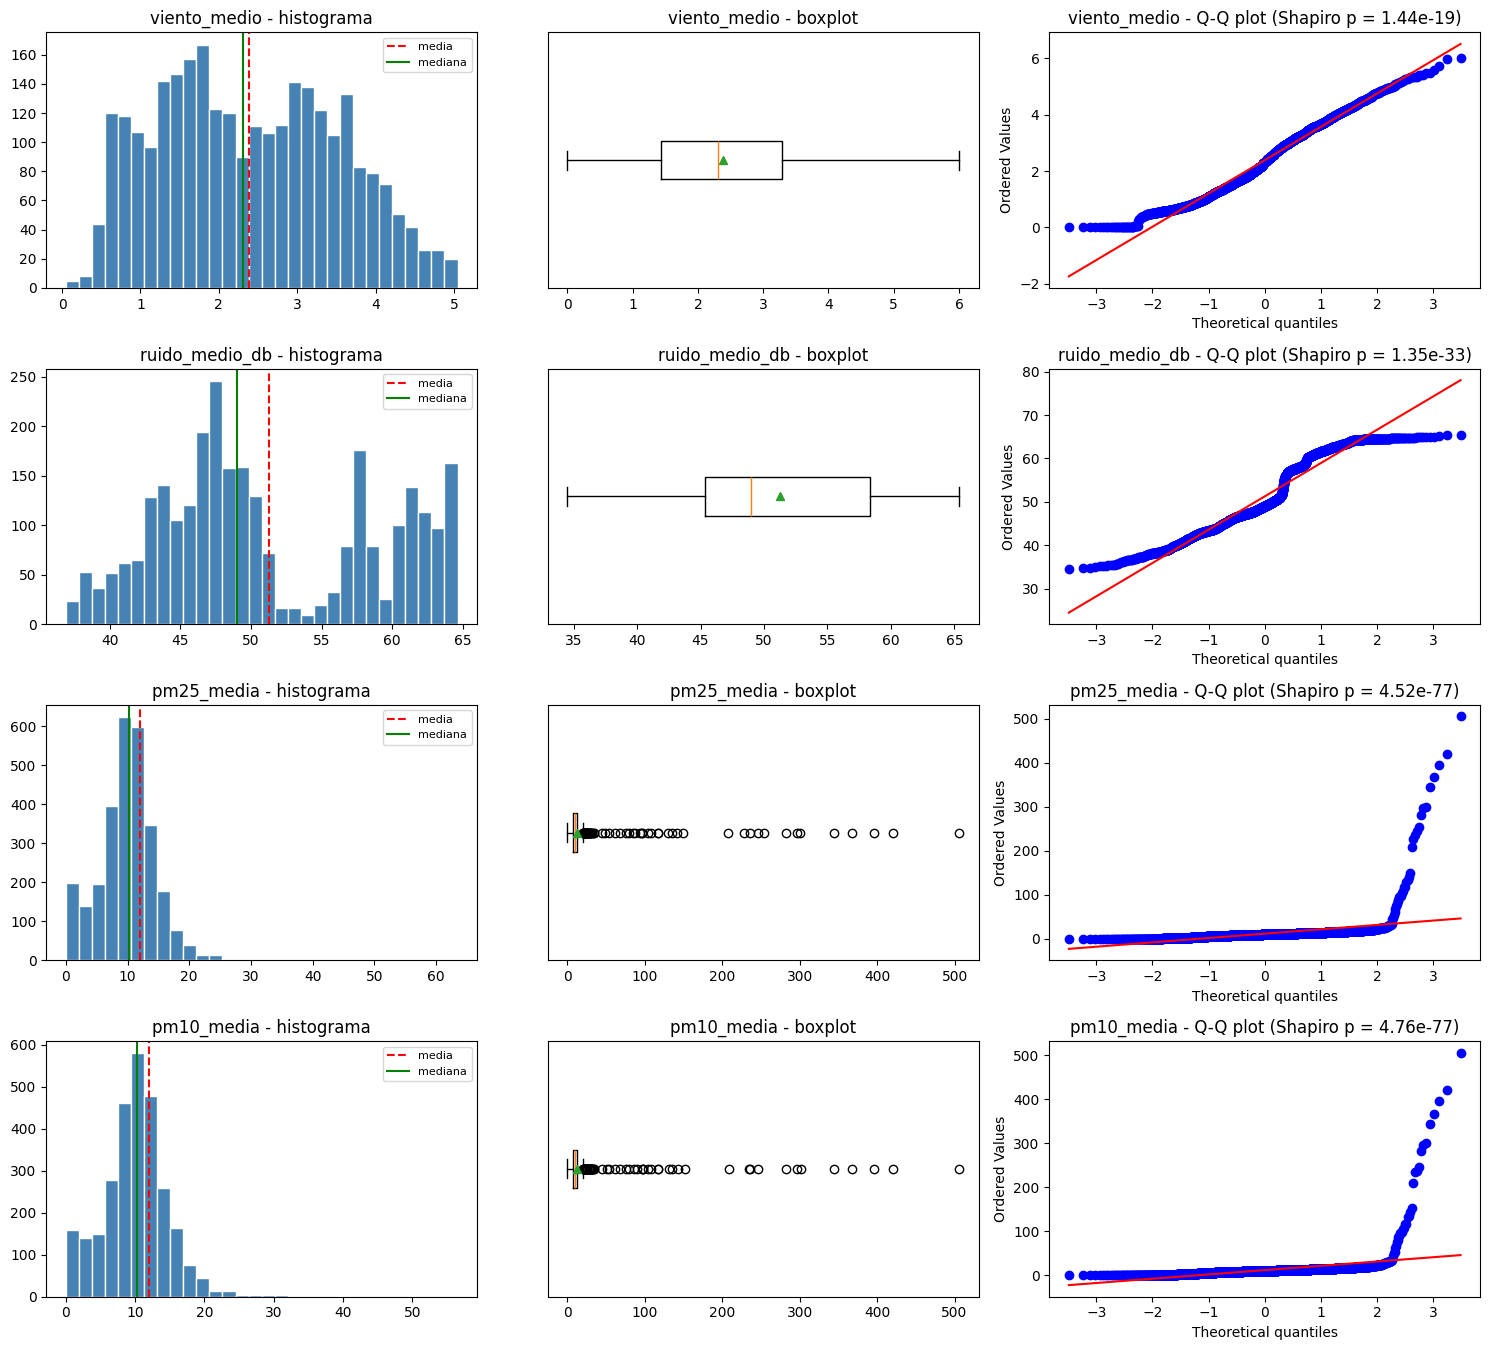

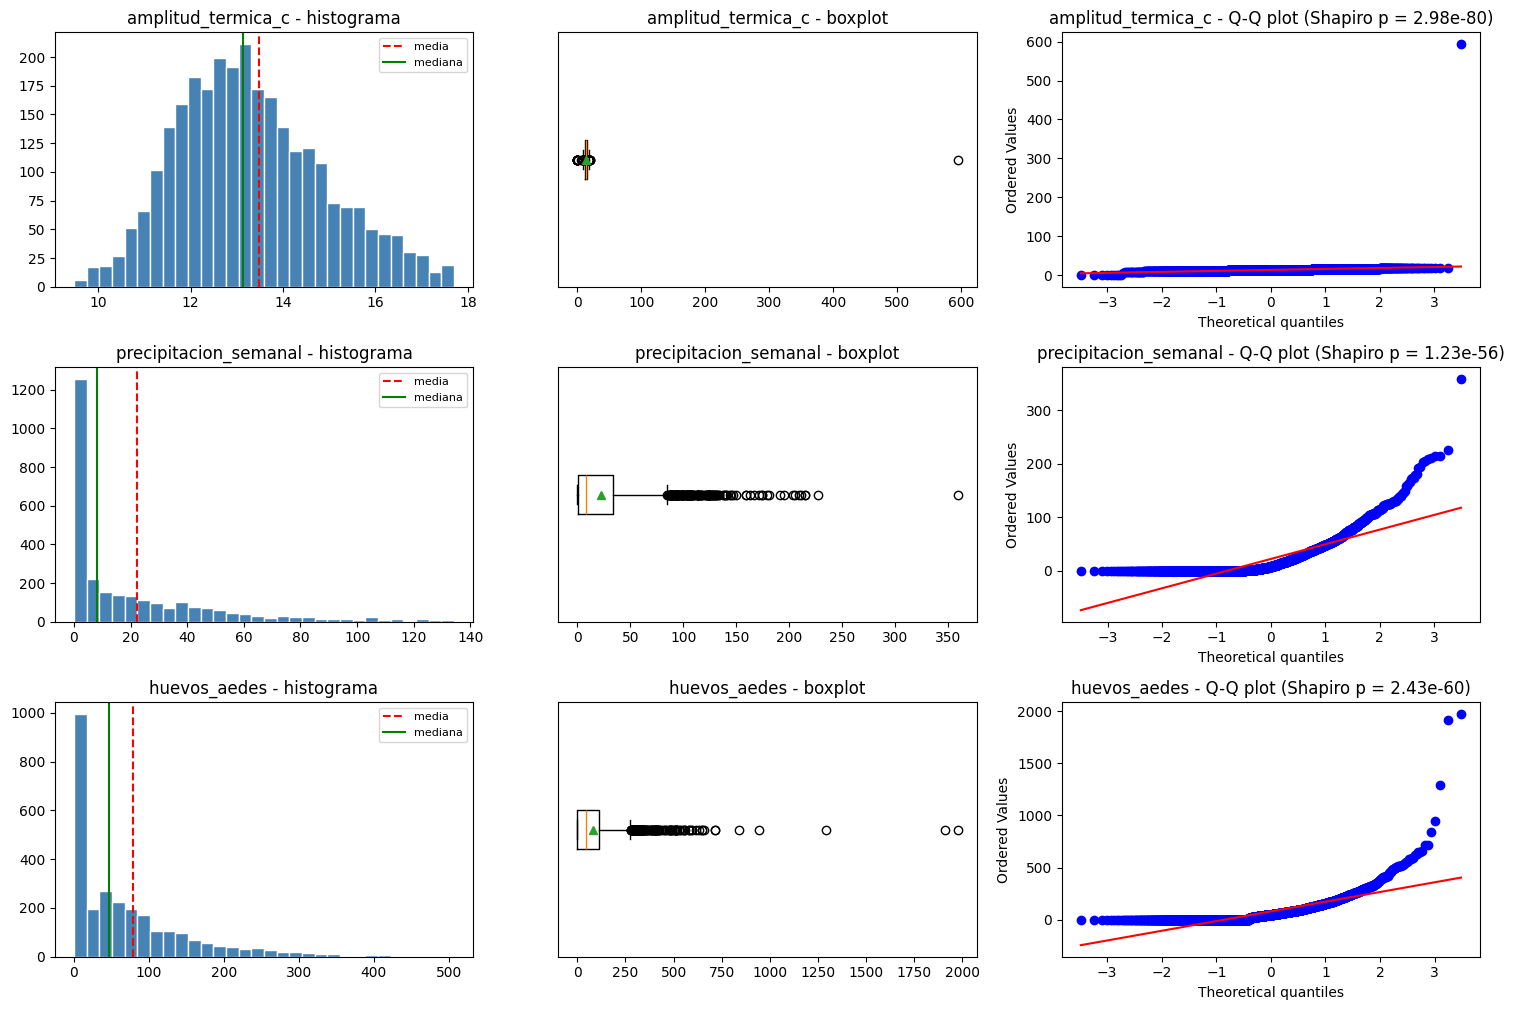

In [13]:
os.makedirs("graficos_univariado", exist_ok=True)  # crea la carpeta donde se guardan las figuras
clave = ["temperatura_media_c", "humedad_media_pct", "radiacion_media", "uv_media", "viento_medio", "ruido_medio_db",
         "pm25_media", "pm10_media", "amplitud_termica_c", "precipitacion_semanal", "huevos_aedes"]  # solo las variables principales; los mín. y máx. quedan en la tabla descriptiva
clave = [v for v in clave if v in num]  # se queda solo con las que existen en la base
por_figura = 4  # variables por figura; cada variable ocupa una fila con 3 gráficos

for i in range(0, len(clave), por_figura):  # recorre las variables en bloques de 4
    bloque = clave[i:i + por_figura]  # variables de esta figura
    fig, axes = plt.subplots(len(bloque), 3, figsize=(15, 3.4 * len(bloque)))  # una fila por variable: histograma, boxplot y Q-Q
    axes = np.atleast_2d(axes)  # asegura que axes siempre sea una matriz, incluso con una sola fila
    for fila, v in enumerate(bloque):  # recorre las variables del bloque
        x = df[v].dropna()  # datos sin vacíos
        lo, hi = x.quantile(0.01), x.quantile(0.99)  # percentiles 1 y 99; solo se usan para el eje del histograma
        rango_hist = (lo, hi) if hi > lo else None  # si la variable casi no varía, se deja el rango completo

        axes[fila, 0].hist(x, bins=30, range=rango_hist, color="steelblue", edgecolor="white")  # histograma; el eje se recorta al 1-99 % para que se vea la forma sin que lo aplaste un valor extremo
        axes[fila, 0].axvline(x.mean(), color="red", linestyle="--", label="media")  # línea de la media
        axes[fila, 0].axvline(x.median(), color="green", linestyle="-", label="mediana")  # línea de la mediana; si se separa de la media hay asimetría
        axes[fila, 0].set_title(f"{v} - histograma")  # título con el nombre de la variable
        axes[fila, 0].legend(fontsize=8)  # leyenda de las dos líneas

        axes[fila, 1].boxplot(x, vert=False, showmeans=True)  # boxplot con todos los datos (sin recortar); los puntos aislados son atípicos
        axes[fila, 1].set_title(f"{v} - boxplot")  # título del boxplot
        axes[fila, 1].set_yticks([])  # quita la marca del eje y, que no aporta

        stats.probplot(x, dist="norm", plot=axes[fila, 2])  # Q-Q plot contra la normal; si los puntos siguen la línea roja, es normal
        axes[fila, 2].set_title(f"{v} - Q-Q plot (Shapiro p = {desc.loc[v, 'p_shapiro']:.3g})")  # título con el valor p de Shapiro-Wilk

    plt.tight_layout()  # acomoda los gráficos para que no se superpongan
    plt.savefig(f"graficos_univariado/variables_{i + 1}_a_{i + len(bloque)}.png", dpi=120, bbox_inches="tight")  # guarda la figura como imagen
    plt.show()  # muestra la figura en pantalla

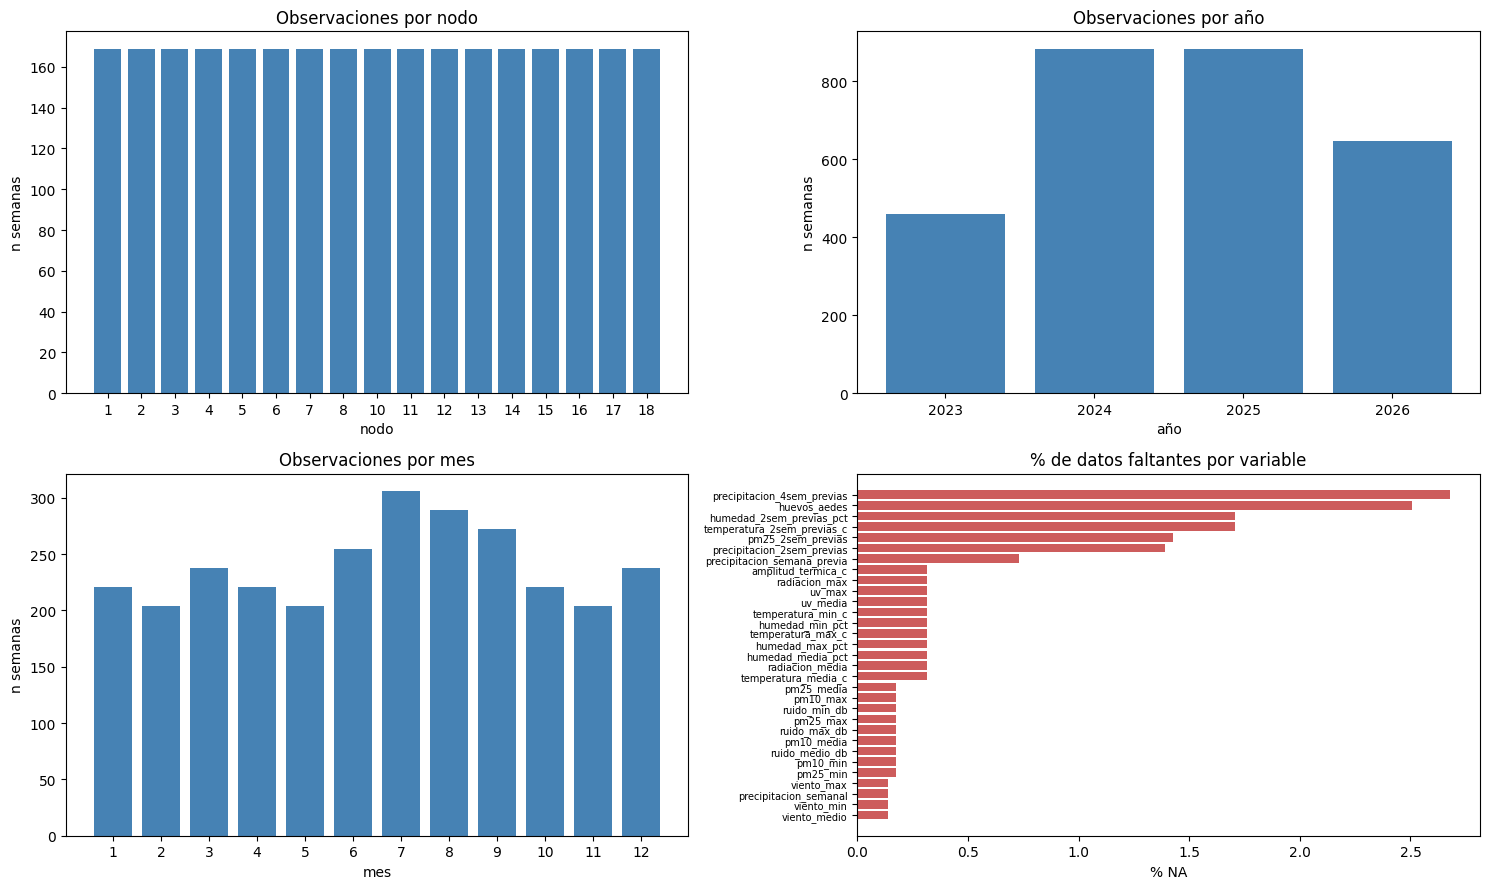

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))  # cuadrícula de 4 gráficos de barras

conteo_nodo = df["nodo"].value_counts().sort_index()  # semanas registradas por nodo; deben ser 169 cada uno
axes[0, 0].bar(conteo_nodo.index.astype(str), conteo_nodo.values, color="steelblue")  # barras por nodo (el 9 no existe)
axes[0, 0].set_title("Observaciones por nodo")  # título
axes[0, 0].set_xlabel("nodo")  # etiqueta del eje x
axes[0, 0].set_ylabel("n semanas")  # etiqueta del eje y

conteo_anio = df["año"].value_counts().sort_index()  # observaciones por año; 2023 y 2026 son años parciales
axes[0, 1].bar(conteo_anio.index.astype(str), conteo_anio.values, color="steelblue")  # barras por año
axes[0, 1].set_title("Observaciones por año")  # título
axes[0, 1].set_xlabel("año")  # etiqueta del eje x
axes[0, 1].set_ylabel("n semanas")  # etiqueta del eje y

conteo_mes = df["inicio_semana"].dt.month.value_counts().sort_index()  # observaciones por mes de inicio de semana
axes[1, 0].bar(conteo_mes.index.astype(str), conteo_mes.values, color="steelblue")  # barras por mes
axes[1, 0].set_title("Observaciones por mes")  # título
axes[1, 0].set_xlabel("mes")  # etiqueta del eje x
axes[1, 0].set_ylabel("n semanas")  # etiqueta del eje y

na_var = desc.loc[desc["n_NA"] > 0, "pct_NA"].sort_values()  # porcentaje de vacíos solo de las variables que sí tienen
axes[1, 1].barh(na_var.index, na_var.values, color="indianred")  # barras horizontales para que se lean los nombres
axes[1, 1].set_title("% de datos faltantes por variable")  # título
axes[1, 1].set_xlabel("% NA")  # etiqueta del eje x
axes[1, 1].tick_params(axis="y", labelsize=7)  # letra pequeña porque son muchas variables

plt.tight_layout()  # acomoda los gráficos
plt.savefig("graficos_univariado/barras_categoricas_y_faltantes.png", dpi=120, bbox_inches="tight")  # guarda la figura
plt.show()  # muestra la figura